In [1]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
from scipy.io import mmread
import helper

# Figure 3

In [2]:
adata_hao = anndata.read_h5ad('../data/hao_adata.h5ad')
adata_hao.obs.value_counts()
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)


KeyboardInterrupt: 

In [ ]:
# for 1000, 5000,10000,50000, 100000, all cells make subsets with the same percentage of each cell type
def _sample(adata: AnnData, size: int, run=0) -> AnnData:
    np.random.seed(run)
    annotations = adata.obs['cell_type']
    annotation_counts = annotations.value_counts()
    selected_cells = []
    # makes sure that each cell type is represented  but keep the proportions
    for annotation in annotation_counts.index:
        cells = annotations[annotations == annotation].index
        n_select = max(1, int(size * (len(cells) / len(annotations))))
        cells = np.random.choice(cells, min(n_select, len(cells)), replace=False)
        selected_cells.extend(cells)
    # if we have less cells than size, we randomly add cells
    while len(selected_cells) < size:
        cell = np.random.choice(annotations.index, 1, replace=False)[0]
        if cell not in selected_cells:
            selected_cells.append(cell)
    return adata[selected_cells, :]
# python
import psutil, threading, time, gc

MB = 1024 * 1024

class PeakRSS:
    def __init__(self, include_children=True, interval=0.01):
        self.proc = psutil.Process()
        self.include_children = include_children
        self.interval = interval
        self.max_rss = 0
        self._stop = threading.Event()
        self._t = None

    def _rss_now(self):
        rss = 0
        try:
            rss += self.proc.memory_info().rss
        except psutil.Error:
            pass
        if self.include_children:
            for c in self.proc.children(recursive=True):
                try:
                    rss += c.memory_info().rss
                except psutil.Error:
                    pass
        return rss

    def start(self):
        self.max_rss = 0
        self._stop.clear()
        self._t = threading.Thread(target=self._run, daemon=True)
        self._t.start()

    def _run(self):
        while not self._stop.is_set():
            self.max_rss = max(self.max_rss, self._rss_now())
            time.sleep(self.interval)

    def stop(self):
        self._stop.set()
        if self._t:
            self._t.join()


In [ ]:
import time
import psutil
import pandas as pd
import numpy as np

# subset sizes (include full dataset size)
subset_sizes = [adata_hao.shape[0], 1000, 5000, 10000,25000, 50000, 100000]

n_runs = 5
runtime_records = []
memory_records = []

proc = psutil.Process()


for n_cells in subset_sizes:
    if n_cells == adata_hao.shape[0]:
        ad = adata_hao
    else:
        ad = _sample(adata_hao, int(n_cells), run=0)
    print(f"Benchmarking rectangle with {n_cells} cells")

    for run in range(n_runs):

        # brief pause to stabilise measurements
        gc.collect()
        time.sleep(0.2)
        baseline_rss = PeakRSS(include_children=True)._rss_now()

        sampler = PeakRSS(include_children=True, interval=0.01)
        sampler.start()
        t0 = time.perf_counter()
        _est, _sig = rp.rectangle(ad, bulks_fino.T)
        t1 = time.perf_counter()
        sampler.stop()

        elapsed_s = t1 - t0
        peak_diff_mb = max(0.0, (sampler.max_rss - baseline_rss) / MB)

        runtime_records.append({"n_cells": int(n_cells), "run": run + 1, "time": elapsed_s})
        memory_records.append({"n_cells": int(n_cells), "run": run + 1, "memory": peak_diff_mb})

# save raw records
runtime_df = pd.DataFrame(runtime_records)
memory_df = pd.DataFrame(memory_records)

runtime_df.to_csv('../data/fig3/rectangle_runtime_qs.csv')
memory_df.to_csv('../data/fig3/rectangle_memory_qs.csv')

In [ ]:
runtime_df = pd.read_csv('../data/fig3/rectangle_runtime_qs.csv')
memory_df = pd.read_csv('../data/fig3/rectangle_memory_qs.csv')
# compute and save summary (mean and std)
runtime_summary = runtime_df.groupby('n_cells')['time'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'time_mean','std':'time_sd'})
memory_summary = memory_df.groupby('n_cells')['memory'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'memory_mean','std':'memory_sd'})

runtime_summary.to_csv('../data/fig3/rectangle_runtime_summary_qs.csv', index=False)
memory_summary.to_csv('../data/fig3/rectangle_memory_summary_qs.csv', index=False)

print("Benchmarking finished. Raw and summary CSVs written to ../data/fig3/")

## Figure 3A

In [ ]:
# memory is in wrong unit
memory_summary['memory_mean'] = memory_summary['memory_mean']/ 1024
memory_summary['memory_sd'] = memory_summary['memory_sd']/ 1024

In [ ]:
df_combined = pd.merge(runtime_summary, memory_summary, on='n_cells')


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style="white")
plt.figure(figsize=(6, 2.5))

colors = ["#FC8D62","#8DA0CB"]
# Both lineplots
ax = sns.lineplot(data=df_combined, x='n_cells', y='time_mean', marker='o', markersize=5, label='time (s)', color=colors[0])
ax = sns.lineplot(data=df_combined, x='n_cells', y='memory_mean', marker='o', markersize=5, label='memory (GiB)', color=colors[1])

# Set logarithmic scale for both axes
plt.xscale('log')
plt.yscale('log')

# Print y values above each marker with an offset to avoid overlapping
for i in range(len(df_combined)):
    time_value = df_combined['time_mean'][i]
    memory_value = df_combined['memory_mean'][i]
    n_cells = df_combined['n_cells'][i]

    if n_cells in [1000, 5000,10000,25000, 50000, 147391]:
        ax.text(n_cells, time_value * 1.1, f"{int(time_value)} s", fontsize=9, ha='center', va='bottom')  # Time values
        ax.text(n_cells, memory_value * 1.1, f"{str(memory_value)[:4]} GiB", fontsize=8, ha='center', va='bottom')  # Memory values
    if n_cells in [100000]:
        ax.text(n_cells, time_value * 0.8, f"{int(time_value)} s", fontsize=9, ha='center', va='top')  # Time values
        ax.text(n_cells, memory_value * 0.8, f"{str(memory_value)[:4]} GiB", fontsize=8, ha='center', va='top')  # Memory values
# Custom ticks and labels for the x and y axes
ax.set_xticks([1000,5000, 25000, 150000])
ax.set_yticks([1, 10, 100])
ax.set_xticklabels(['1,000', '5,000', '50,000','150,000'])
ax.set_yticklabels(['1', '10', '100'])

# Set y-axis limits
ax.set_ylim(bottom=0, top=250)
ax.set_xlim(left=700, right=250000)

# Labels and layout
plt.xlabel('Number of cells')
plt.ylabel('value')
#title for the plot
plt.title('Memory and time usage')


# Move legend to the right
legend = plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

# legend labels
plt.tight_layout()
# save
plt.savefig('../figures/fig3a_rectangle_benchmark_qs.pdf')

# Show the plot
plt.show()

## Figure 3B

# Autogenes


In [ ]:
import time
import psutil
import pandas as pd
import numpy as np
import scanpy as sc
import anndata
import autogenes as ag

# subset sizes (include full dataset size)


n_runs = 5
runtime_records = []
memory_records = []

proc = psutil.Process()

adata_hao = anndata.read_h5ad('../data/hao_adata.h5ad')
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)
sc.pp.normalize_total(adata_hao, target_sum=1e6)
subset_sizes = [adata_hao.shape[0]]
for n_cells in subset_sizes:
    # convert to cpm
    sc.pp.normalize_total(adata_hao, target_sum=1e6)
    print(f"Benchmarking rectangle with {n_cells} cells")

    for run in range(n_runs):
        print(f"Running run {run}")
        # brief pause to stabilise measurements
        gc.collect()
        time.sleep(0.2)
        baseline_rss = PeakRSS(include_children=True)._rss_now()

        sampler = PeakRSS(include_children=True, interval=0.01)
        sampler.start()
        t0 = time.perf_counter()
        ag.init(adata_hao,celltype_key='cell_type')
        ag.optimize(ngen=500,seed=0)
        coef = ag.deconvolve(bulks_fino.T)

        t1 = time.perf_counter()
        sampler.stop()

        elapsed_s = t1 - t0
        peak_diff_mb = max(0.0, (sampler.max_rss - baseline_rss) / MB)

        runtime_records.append({"n_cells": int(n_cells), "run": run + 1, "time": elapsed_s})
        memory_records.append({"n_cells": int(n_cells), "run": run + 1, "memory": peak_diff_mb})
        print(f"Time: {elapsed_s}s")

# save raw records
runtime_df = pd.DataFrame(runtime_records)
memory_df = pd.DataFrame(memory_records)

runtime_df.to_csv('../data/fig3/autogenes_runtime.csv')
memory_df.to_csv('../data/fig3/autogenes_memory.csv')

In [ ]:
runtime_df = pd.read_csv('../data/fig3/autogenes_runtime.csv')
memory_df = pd.read_csv('../data/fig3/autogenes_memory.csv')
# compute and save summary (mean and std)
runtime_summary = runtime_df.groupby('n_cells')['time'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'time_mean','std':'time_sd'})
memory_summary = memory_df.groupby('n_cells')['memory'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'memory_mean','std':'memory_sd'})

runtime_summary.to_csv('../data/fig3/autogenes_runtime_summary.csv', index=False)
memory_summary.to_csv('../data/fig3/autogenes_memory_summary.csv', index=False)

In [ ]:
runtimes_autogenes = pd.read_csv('../data/fig3/autogenes_runtime_summary.csv')
memory_autogenes = pd.read_csv('../data/fig3/autogenes_memory_summary.csv')
memory_autogenes[['memory_mean']] = memory_autogenes[['memory_mean']] / 1024  # convert to GB
memory_autogenes[['memory_sd']] = memory_autogenes[['memory_sd']] / 1024
df_combined = pd.merge(runtimes_autogenes, memory_autogenes, on='n_cells')

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_style("white")
# Load data
rect_mem = pd.read_csv('../data/fig3/rectangle_memory_summary_qs.csv')
rect_run = pd.read_csv('../data/fig3/rectangle_runtime_summary_qs.csv')
autogenes_mem = pd.read_csv('../data/fig3/autogenes_memory_summary.csv')
autogenes_run = pd.read_csv('../data/fig3/autogenes_runtime_summary.csv')
scdc = pd.read_csv('../data/fig3/scdc.csv')
music = pd.read_csv('../data/fig3/music.csv')

# Rectangle data
n_cells_target = rect_mem['n_cells'].max()
rect_mem_row = rect_mem[rect_mem['n_cells'] == n_cells_target].iloc[0]
rect_run_row = rect_run[rect_run['n_cells'] == n_cells_target].iloc[0]
autogenes_mem_row = autogenes_mem[autogenes_mem['n_cells'] == n_cells_target].iloc[0]
autogenes_run_row = autogenes_run[autogenes_run['n_cells'] == n_cells_target].iloc[0]

rect_time_mean = rect_run_row['time_mean']
rect_time_sd = rect_run_row['time_sd']
rect_mem_mean = rect_mem_row['memory_mean']
rect_mem_sd = rect_mem_row['memory_sd']
autogenes_time_mean = autogenes_run_row['time_mean']
autogenes_time_sd = autogenes_run_row['time_sd']
autogenes_mem_mean = autogenes_mem_row['memory_mean']
autogenes_mem_sd = autogenes_mem_row['memory_sd']

# SCDC data
scdc_time_mean = scdc['Time_s'].mean()
scdc_time_sd = scdc['Time_s'].std()

# Music data
music_time_mean = music['Time_s'].mean()
music_time_sd = music['Time_s'].std()

music_mem_mean = music['Peak_Mem_MiB'].mean()
music_mem_sd = music['Peak_Mem_MiB'].std()

# Verify SCDC Memory Units
scdc_mem_raw = scdc['Peak_Mem_MiB'].mean()
print(f"SCDC raw memory val: {scdc_mem_raw}")

# If raw value > 1e6, it's definitely not MB (would be >1TB). Assuming Words.
if scdc_mem_raw > 1e6:
    print("Converting SCDC memory from Words to MiB")
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean() * 8 / (1024 * 1024)
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std() * 8 / (1024 * 1024)
else:
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean()
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std()

# Create DataFrame for plotting
df_res = pd.DataFrame({
    'Method': ['Rectangle', 'SCDC' ,'Autogenes', 'MuSiC'],
    'Time_Mean': [rect_time_mean, scdc_time_mean, autogenes_time_mean, music_time_mean],
    'Time_SD': [rect_time_sd, scdc_time_sd, autogenes_time_sd, music_time_sd],
    'Memory_Mean': [rect_mem_mean, scdc_mem_mean, autogenes_mem_mean, music_mem_mean],
    'Memory_SD': [rect_mem_sd, scdc_mem_sd, autogenes_mem_sd, music_mem_sd]
})

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
colors = ['#1f77b4', '#B3B3B3', '#ff7f0e']
# log y axis


# Runtime Plot
axes[0].bar(df_res['Method'], df_res['Time_Mean'], yerr=df_res['Time_SD'], capsize=5, color=colors)
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime Comparison')

# Memory Plot
axes[1].bar(df_res['Method'], df_res['Memory_Mean'], yerr=df_res['Memory_SD'], capsize=5, color=colors)
axes[1].set_ylabel('Memory (MiB)')
axes[1].set_title('Memory Comparison')

plt.tight_layout()
plt.savefig('../figures/fig3c_scdc_rectangle_comparison.pdf', dpi=300)
plt.show()




# Figure 3D

In [ ]:

cell_palette = {
    'Brca': '#66C2A5',
    'Luad': '#FC8D62',
    'Lusc': '#8DA0CB',
    'CPE': '#FC8D62',
    'B cells': '#66C2A5',
    'Macrophages': '#FC8D62',
    'Macrophages-Monocytes': '#FC8D62',
    'mDC': '#8DA0CB',
    'mDCs': '#8DA0CB',
    'Monocytes': '#E78AC3',
    'Monocytes classical': '#E580C0',
    'Monocytes non-classical': '#D085B9',
    'NK cells': '#DDD700',
    'T and NK cells': '#DDD700',
    'T cells': '#FFD92F',
    'T cells CD4 conv': '#B3B3B3',
    'T cells CD4': '#B3B3B3',
    'T cells CD4 non-reg': '#B3B3B3',
    'T cells CD4 Total': '#B3B3B3',
    'T cells CD8': '#A6D854',
    'T cells CD8 activated': '#A5D753',
    'T cells CD8 naive': '#A0D04B',
    'T cells CD8 t.e.': '#A0A410',
    'T cells NK-like': '#DBD500',
    'Tregs': '#52A0A0',
    'pDC': '#E5C494',
    'pDCs': '#E5C490',
    'cDC1': '#A3C292',
    'cDC2': '#A1C090',
    'Neutrophils': '#B3B3B3',
    'Stromal cells': '#66C2A5',
    'Plasma cells': '#FC8D62',
    'ILC': '#8DA0CB',
    'Platelet': '#E78AC3',
    'all': '#000000'
}

In [ ]:
import pandas as pd
import helper
import rectanglepy as rp
import anndata
lambrechts_folder = '../data/fig3/pseudo_bulk_resolution/lambrechts_resolution_analysis_sim'
lambrechts_counts = pd.read_csv(lambrechts_folder + '/lambrecht_counts.csv.zip', index_col=0)

In [30]:
annotations_normal =pd.read_csv(lambrechts_folder + '/lambrechts_annotations_normal.csv', index_col=0).squeeze()
annotations_coarse = pd.read_csv(lambrechts_folder + '/lambrechts_annotations_coarse.csv', index_col=0).squeeze()
annotations_fine = pd.read_csv(lambrechts_folder + '/lambrechts_annotations_fine.csv', index_col=0).squeeze()

In [35]:
annotations_fine.index = lambrechts_counts.columns
annotations_coarse.index = lambrechts_counts.columns
annotations_normal.index = lambrechts_counts.columns
# rename column 'x' to 'cell_type'
annotations_fine.name = 'cell_type'
annotations_normal.name = 'cell_type'
annotations_coarse.name = 'cell_type'

In [ ]:
lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_fine.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations.csv')

In [ ]:

lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_coarse.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations_coarse.csv')

In [44]:

lambrechts_adata = anndata.AnnData(X=lambrechts_counts.T, obs=annotations_normal.to_frame(name="cell_type"))
for i in range(1,6):
    bulks = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_tpm.csv', index_col=0)
    estimations, signature = rp.rectangle(lambrechts_adata, bulks.T)
    estimations.to_csv(lambrechts_folder + f'/replicate_{i}/estimations_normal.csv')


2026-02-28 16:13:43.744 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 17146 common genes between bulks and single-cell data
2026-02-28 16:14:31.451 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/pp/create_signature.py:181: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bootstrapped_signature[f"{celltype}_{i}"] = list(summed_rows)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/pp/create_signature.py:181: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  C

Polishing not needed - no active set detected at optimal point


2026-02-28 16:16:59.564 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 1
2026-02-28 16:16:59.567 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 4
2026-02-28 16:16:59.612 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 0
2026-02-28 16:16:59.615 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 3
2026-02-28 16:16:59.706 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 6
2026-02-28 16:16:59.744 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-02-28 16:17:15.992 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 5
2026-02-28 16:17:16.056 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 8


...

2026-02-28 16:32:39.912 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 5
2026-02-28 16:32:39.953 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 4


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-02-28 16:32:41.992 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 0
2026-02-28 16:32:42.075 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 3


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-02-28 16:32:52.549 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 8
2026-02-28 16:32:53.415 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 9


In [95]:

lambrechts_fine_estimations = []
lambrechts_fine_true =[]
lambrechts_normal_estimations = []
lambrechts_normal_true =[]
lambrechts_coarse_estimations = []
lambrechts_coarse_true =[]
for i in range(1,6):
    fine_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_fine.csv', index_col=0)
    fine_estimation = fine_estimation.drop('Unknown', axis=1)
    fine_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_fine_annot_facs.csv', index_col=0)
    normal_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_normal.csv', index_col=0)
    normal_estimation = normal_estimation.drop('Unknown', axis=1)
    normal_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_normal_annot_facs.csv', index_col=0)
    coarse_estimation = pd.read_csv(lambrechts_folder + f'/replicate_{i}/estimations_coarse.csv', index_col=0)
    coarse_estimation = coarse_estimation.drop('Unknown', axis=1)
    coarse_true = pd.read_csv(lambrechts_folder + f'/replicate_{i}/lambrechts_resolution_analysis_sim_coarse_annot_facs.csv', index_col=0)
    lambrechts_fine_estimations.append(fine_estimation)
    lambrechts_normal_estimations.append(normal_estimation)
    lambrechts_coarse_estimations.append(coarse_estimation)
    lambrechts_fine_true.append(fine_true)
    lambrechts_normal_true.append(normal_true)
    lambrechts_coarse_true.append(coarse_true)

In [96]:
lambrechts_true = lambrechts_coarse_true[0]
lambrechts_estimation = lambrechts_coarse_estimations[0].T
    # sort columns and index to match
lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))


In [97]:
lambrechts_estimation

,mirror_db_sample1,mirror_db_sample10,mirror_db_sample2,mirror_db_sample3,mirror_db_sample4,mirror_db_sample5,mirror_db_sample6,mirror_db_sample7,mirror_db_sample8,mirror_db_sample9
B cells,0.017030,0.046573,0.065231,0.052665,0.082637,0.009100,0.071393,0.047844,0.030270,0.064934
Endothelial cells,0.114981,0.140422,0.108095,0.121217,0.092338,0.042971,0.083947,0.143074,0.111301,0.036780
Epithelial cells,0.101426,0.063940,0.094338,0.051639,0.062602,0.062297,0.042005,0.047630,0.064124,0.081133
Macrophages-Monocytes,0.160057,0.055579,0.139589,0.178784,0.120587,0.214524,0.078969,0.140098,0.206663,0.093115
Mast cells,0.008687,0.001917,0.010397,0.002739,0.018450,0.008747,0.010528,0.020658,0.007829,0.024487
Neutrophils,0.011709,0.020142,0.061091,0.012663,0.020941,0.021834,0.045057,0.012475,0.025743,0.051889
Plasma cells,0.021669,0.013482,0.021938,0.023629,0.015536,0.010323,0.003825,0.021199,0.006671,0.004922
Stromal cells,0.155470,0.089231,0.062043,0.057277,0.029186,0.035006,0.030469,0.089093,0.084780,0.085618
T and NK cells,0.180459,0.286319,0.230362,0.265641,0.350612,0.336006,0.332306,0.277759,0.337322,0.331286
Tumor cells,0.173661,0.228938,0.154206,0.181972,0.178650,0.219949,0.225911,0.117598,0.071388,0.160908


In [98]:
lambrechts_true

,mirror_db_sample1,mirror_db_sample10,mirror_db_sample2,mirror_db_sample3,mirror_db_sample4,mirror_db_sample5,mirror_db_sample6,mirror_db_sample7,mirror_db_sample8,mirror_db_sample9
B cells,0.018408,0.049390,0.068013,0.052257,0.085565,0.011347,0.074833,0.040621,0.034623,0.068534
Endothelial cells,0.095290,0.134295,0.105739,0.143705,0.093132,0.044894,0.073808,0.139662,0.098269,0.044522
Epithelial cells,0.102870,0.069922,0.114772,0.089074,0.083236,0.074001,0.068683,0.052487,0.071792,0.108554
Macrophage alveolar,0.038441,0.039401,0.030818,0.042162,0.019790,0.078934,0.028703,0.041990,0.071792,0.033017
Macrophages-Monocytes,0.148349,0.034406,0.134963,0.147268,0.136787,0.174149,0.063557,0.123688,0.124745,0.075538
Mast cells,0.008663,0.001665,0.010627,0.002375,0.018626,0.008880,0.011276,0.021451,0.008147,0.025513
Neutrophils,0.021657,0.004440,0.031881,0.001188,0.000582,0.000987,0.036392,0.004564,0.018330,0.028014
Plasma cells,0.021657,0.014983,0.022848,0.026722,0.018626,0.009867,0.004613,0.020539,0.005601,0.005003
Stromal cells,0.153221,0.103219,0.069075,0.051069,0.039581,0.038974,0.036392,0.093108,0.092668,0.078039
T and NK cells,0.198159,0.296892,0.244952,0.268409,0.346333,0.329058,0.337775,0.277955,0.325866,0.337169


lambrechts

In [99]:

lambrechts_fine_evaluations = []
lambrechts_fine_evalutaions_cell_types = []
lambrechts_normal_evaluations = []
lambrechts_normal_evaluations_cell_types = []
lambrechts_coarse_evaluations = []
lambrechts_coarse_evaluations_cell_types = []
fine_cell_types = None
normal_cell_types = None
coarse_cell_types = None
for i in range(5):
    print(i)
    lambrechts_true = lambrechts_fine_true[i]
    lambrechts_estimation = lambrechts_fine_estimations[i].T
    # sort columns and index to match
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    fine_cell_types = lambrechts_estimation.index
    fine_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(fine_evaluation)
    lambrechts_fine_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_fine_evalutaions_cell_types.append((rsmes, rs, ps))

    lambrechts_true = lambrechts_normal_true[i]
    lambrechts_estimation = lambrechts_normal_estimations[i].T
    lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))
    lambrechts_estimation = lambrechts_estimation[lambrechts_estimation.index != "Tregs"]
    # macrophae is macrophage and macrophage alveolar  summed then remove macrophage alveolar
    lambrechts_true = lambrechts_true.T
    lambrechts_true["Macrophages"] = lambrechts_true["Macrophages"] + lambrechts_true["Macrophage alveolar"]
    lambrechts_true = lambrechts_true.T
    lambrechts_true = lambrechts_true[lambrechts_true.index != "Macrophage alveolar"]

    # sort columns and index to match
# sort columns and index to match
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)

    normal_cell_types = lambrechts_estimation.index
    normal_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(normal_evaluation)
    lambrechts_normal_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_normal_evaluations_cell_types.append((rsmes, rs, ps))

    lambrechts_true = lambrechts_coarse_true[i]
    lambrechts_estimation = lambrechts_coarse_estimations[i].T
    # sort columns and index to match
    lambrechts_estimation.index = lambrechts_estimation.index.map(lambda x: str(x).replace("_", " "))
    lambrechts_true = lambrechts_true.T
    lambrechts_true["Macrophages-Monocytes"] = lambrechts_true["Macrophages-Monocytes"] + lambrechts_true["Macrophage alveolar"]
    lambrechts_true = lambrechts_true.T
    lambrechts_true = lambrechts_true[lambrechts_true.index != "Macrophage alveolar"]
    lambrechts_true = lambrechts_true.sort_index().sort_index(axis=1)
    lambrechts_estimation = lambrechts_estimation.sort_index().sort_index(axis=1)
    coarse_cell_types = lambrechts_estimation.index
    coarse_evaluation = helper.create_evaluation_df(lambrechts_true, lambrechts_estimation)
    rsme, r, p = helper.evaulate_total_df(coarse_evaluation)
    lambrechts_coarse_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(lambrechts_true, lambrechts_estimation)
    lambrechts_coarse_evaluations_cell_types.append((rsmes, rs, ps))

0
1
2
3
4


In [100]:

# average values
lambrechts_fine_rsmes = [x[0] for x in lambrechts_fine_evaluations]
lambrechts_fine_rsme_avg = sum(lambrechts_fine_rsmes) / len(lambrechts_fine_rsmes)
lambrechts_fine_r_values = [x[1] for x in lambrechts_fine_evaluations]
lambrechts_fine_r_avg = sum(lambrechts_fine_r_values) / len(lambrechts_fine_r_values)
lambrechts_normal_rsmes = [x[0] for x in lambrechts_normal_evaluations]
lambrechts_normal_rsme_avg = sum(lambrechts_normal_rsmes) / len(lambrechts_normal_rsmes)
lambrechts_normal_r_values = [x[1] for x in lambrechts_normal_evaluations]
lambrechts_normal_r_avg = sum(lambrechts_normal_r_values) / len(lambrechts_normal_r_values)
lambrechts_coarse_rsmes = [x[0] for x in lambrechts_coarse_evaluations]
lambrechts_coarse_rsme_avg = sum(lambrechts_coarse_rsmes) / len(lambrechts_coarse_rsmes)
lambrechts_coarse_r_values = [x[1] for x in lambrechts_coarse_evaluations]
lambrechts_coarse_r_avg = sum(lambrechts_coarse_r_values) / len(lambrechts_coarse_r_values)

lambrechts_fine_rsmes_cell = [x[0] for x in lambrechts_fine_evalutaions_cell_types]
lambrechts_fine_rsme_cell_avg = pd.DataFrame(lambrechts_fine_rsmes_cell).mean()
# set index to fine_cell_types
lambrechts_fine_rsme_cell_avg.index = fine_cell_types
lambrechts_fine_r_cell = [x[2] for x in lambrechts_fine_evalutaions_cell_types]
lambrechts_fine_r_cell_avg = pd.DataFrame(lambrechts_fine_r_cell).mean()
# set index to fine_cell_types
lambrechts_fine_r_cell_avg.index = fine_cell_types
lambrechts_normal_rsmes_cell = [x[0] for x in lambrechts_normal_evaluations_cell_types]
lambrechts_normal_rsme_cell_avg = pd.DataFrame(lambrechts_normal_rsmes_cell).mean()
lambrechts_normal_rsme_cell_avg.index = normal_cell_types
lambrechts_normal_r_cell = [x[2] for x in lambrechts_normal_evaluations_cell_types]
lambrechts_normal_r_cell_avg = pd.DataFrame(lambrechts_normal_r_cell).mean()
lambrechts_normal_r_cell_avg.index = normal_cell_types
lambrechts_coarse_rsmes_cell = [x[0] for x in lambrechts_coarse_evaluations_cell_types]
lambrechts_coarse_rsme_cell_avg = pd.DataFrame(lambrechts_coarse_rsmes_cell).mean()
lambrechts_coarse_rsme_cell_avg.index = coarse_cell_types
lambrechts_coarse_r_cell = [x[2] for x in lambrechts_coarse_evaluations_cell_types]
lambrechts_coarse_r_cell_avg = pd.DataFrame(lambrechts_coarse_r_cell).mean()
lambrechts_coarse_r_cell_avg.index = coarse_cell_types

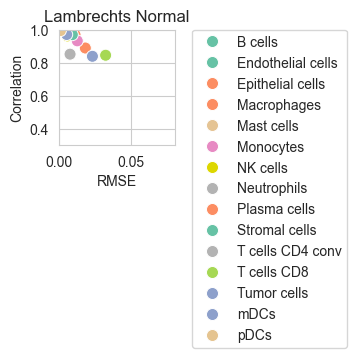

In [101]:
# plot results
import seaborn as sns
import matplotlib.pyplot as plt
# Additions for missing keys
cell_palette.update({
    # Endothelial / vascular
    'Endothelial_ACKR1': '#66C2A5',                 # stromal-like green
    'Endothelial_CXCL12': '#66C2A5',
    'Endothelial_Lymphatic_LYVE1': '#66C2A5',
    'Endothelial_RGS5': '#66C2A5',

    # CAFs / stromal
    'CAFs_MSC_iCAF-like': '#66C2A5',
    'CAFs_myCAF-like': '#66C2A5',
    'Myoepithelial': '#66C2A5',

    # Luminal / epithelial (non-cancer)
    'Mature_Luminal': '#FC8D62',
    'Luminal_Progenitors': '#FC8D62',

    # PVL states (not sure what PVL stands for in your context; use luminal family)
    'PVL_Immature': '#FC8D62',
    'PVL_Differentiated': '#FC8D62',
    'Cycling_PVL': '#B3B3B3',

    # B lineage
    'B_cells_Naive': '#66C2A5',
    'B_cells_Memory': '#66C2A5',
    'Plasmablasts': '#FC8D62',

    # NK / T / NKT
    'NK_cells': '#DDD700',
    'NKT_cells': '#DDD700',
    'T_cells_CD4+': '#B3B3B3',
    'T_cells_CD8+': '#A6D854',
    'Cycling_T-cells': '#B3B3B3',

    # Myeloid
    'Monocyte': '#E78AC3',
    'Macrophage': '#FC8D62',
    'DCs': '#8DA0CB',
    'Cycling_Myeloid': '#B3B3B3',

    # Cancer states (group into a consistent cancer palette)
    'Cancer_Basal_SC': '#8DA0CB',                   # similar to "Lusc" family
    'Cancer_LumA_SC': '#66C2A5',                    # similar to "Brca" family
    'Cancer_LumB_SC': '#FC8D62',                    # similar to "Luad/CPE" family
    'Cancer_Her2_SC': '#E78AC3',                    # standout magenta family
    'Cancer_Cycling': '#B3B3B3',
    'Cancer_Cycling': '#B3B3B3',  # (duplicate key safe; last wins)
    # Missing after index rename
    'Tumor cells': '#8DA0CB',
    'Epithelial cells': '#FC8D62',
    'Endothelial cells': '#66C2A5',
    'Mast cells': '#E5C494',

    # Lambrechts fine-grained labels (underscore variants)
    'Fibroblasts_adventitial': '#66C2A5',
    'Fibroblasts_peribronchial': '#66C2A5',
    'Fibroblasts_alveolar': '#66C2A5',
    'Pericytes': '#66C2A5',
    'Endothelial_cells_capillary': '#66C2A5',
    'Endothelial_cells_arterial': '#66C2A5',
    'Endothelial_cells_venous': '#66C2A5',
    'Endothelial_cells_lymphatic': '#66C2A5',
    'B_cells': '#66C2A5',
    'Plasma_cells': '#FC8D62',
    'Monocytes_classical': '#E580C0',
    'Monocytes_non-classical': '#D085B9',
    'Macrophage_alveolar': '#FC8D62',
    'Mast_cells': '#E5C494',
    'T_cells_CD4_non-reg': '#B3B3B3',
    'T_cells_CD8_naive': '#A0D04B',
    'T_cells_CD8_activated': '#A5D753',
    'T_cells_CD8_effector_memory': '#A6D854',
    'T_cells_CD8_terminally_exhausted': '#A0A410',
    'T_cells_NK-like': '#DBD500',
    'Alveolar_cells_type_1': '#FC8D62',
    'Alveolar_cells_type_2': '#FC8D62',
    'Ciliated': '#FC8D62',
    'Club': '#FC8D62',
    'Tumor_cells_LUAD': '#FC8D62',
    'Tumor_cells_LUAD_EMT': '#66C2A5',
    'Tumor_cells_LUAD_mitotic': '#B3B3B3',
    'Tumor_cells_LUSC': '#8DA0CB',
    'Tumor_cells_LUSC_mitotic': '#B3B3B3',
    'Tumor_cells_NSCLC_mixed': '#8DA0CB',

})
color_palette = sns.color_palette("tab20")[0:8]
color_palette.append((0.01, 0.01, 0.01))
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(0.3, 1)
sns.scatterplot(data=lambrechts_normal_r_cell_avg.to_frame(name='Correlation').join(lambrechts_normal_rsme_cell_avg.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=lambrechts_normal_r_cell_avg.index, s=75, palette=cell_palette)
plt.title('Lambrechts Normal')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_lambrechts_normal.pdf', bbox_inches='tight')
plt.show()


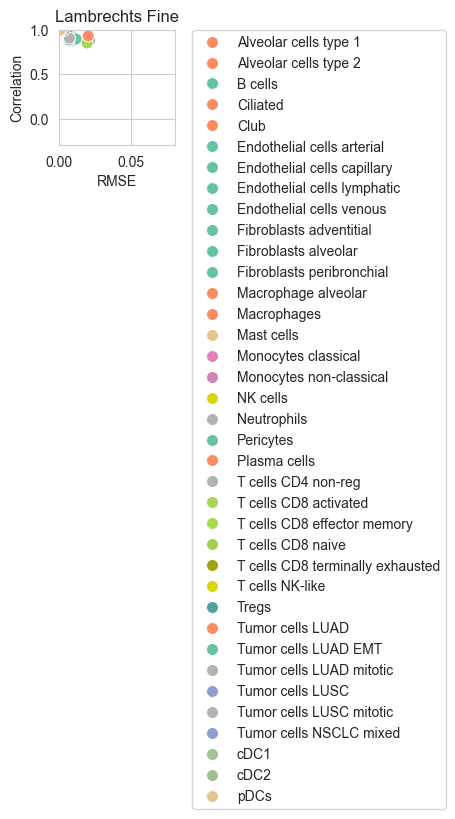

In [102]:
cell_palette.update({
    # ---- T cells / NK / NKT subclusters ----
    'T_cells_c0_CD4+_CCR7': '#B3B3B3',              # CD4 family
    'T_cells_c1_CD4+_IL7R': '#B3B3B3',              # CD4 family
    'T_cells_c2_CD4+_T-regs_FOXP3': '#52A0A0',      # Tregs
    'T_cells_c3_CD4+_Tfh_CXCL13': '#B3B3B3',        # CD4 family
    'T_cells_c4_CD8+_ZFP36': '#A6D854',             # CD8 family
    'T_cells_c5_CD8+_GZMK': '#A6D854',              # CD8 family
    'T_cells_c6_IFIT1': '#FFD92F',                  # general T cells (or interferon-ish)
    'T_cells_c7_CD8+_IFNG': '#A6D854',              # CD8 effector
    'T_cells_c8_CD8+_LAG3': '#A6D854',              # exhausted CD8
    'T_cells_c9_NK_cells_AREG': '#DDD700',          # NK family
    'T_cells_c10_NKT_cells_FCGR3A': '#DDD700',      # NKT/NK-like
    'T_cells_c11_MKI67': '#B3B3B3',                 # cycling -> neutral

    # ---- Myeloid subclusters ----
    'Myeloid_c0_DC_LAMP3': '#8DA0CB',               # DC family
    'Myeloid_c3_cDC1_CLEC9A': '#A3C292',            # cDC1 (matches your cDC1)
    'Myeloid_c11_cDC2_CD1C': '#A1C090',             # cDC2 (matches your cDC2)
    'Myeloid_c4_DCs_pDC_IRF7': '#E5C494',           # pDC family
    'Myeloid_c12_Monocyte_1_IL1B': '#E78AC3',       # monocytes
    'Myeloid_c8_Monocyte_2_S100A9': '#E78AC3',      # monocytes
    'Myeloid_c7_Monocyte_3_FCGR3A': '#E78AC3',      # monocytes (non-classical-ish but keep same family)
    'Myeloid_c5_Macrophage_3_SIGLEC1': '#FC8D62',   # macrophage family
    'Myeloid_c10_Macrophage_1_EGR1': '#FC8D62',     # macrophage family
    'Myeloid_c9_Macrophage_2_CXCL10': '#FC8D62',    # macrophage family
    'Myeloid_c1_LAM1_FABP5': '#FC8D62',             # macrophage-like (LAM)
    'Myeloid_c2_LAM2_APOE': '#FC8D62',              # macrophage-like (LAM)

    # ---- CAF subclusters ----
    'CAFs_Transitioning_s3': '#66C2A5',
    'CAFs_MSC_iCAF-like_s1': '#66C2A5',
    'CAFs_MSC_iCAF-like_s2': '#66C2A5',
    'CAFs_myCAF_like_s4': '#66C2A5',
    'CAFs_myCAF_like_s5': '#66C2A5',

    # ---- PVL subclusters ----
    'PVL_Immature_s1': '#FC8D62',
    'PVL_Immature_s2': '#FC8D62',
    'PVL_Differentiated_s3': '#FC8D62',
    # Lambrechts fine labels with spaces
    'Tumor cells NSCLC mixed': '#8DA0CB',
    'Tumor cells LUSC': '#8DA0CB',
    'Alveolar cells type 2': '#FC8D62',
    'Tumor cells LUSC mitotic': '#B3B3B3',
    'Tumor cells LUAD': '#FC8D62',
    'Endothelial cells lymphatic': '#66C2A5',
    'Fibroblasts alveolar': '#66C2A5',
    'Macrophage alveolar': '#FC8D62',
    'Fibroblasts peribronchial': '#66C2A5',
    'Fibroblasts adventitial': '#66C2A5',
    'Endothelial cells arterial': '#66C2A5',
    'Tumor cells LUAD EMT': '#66C2A5',
    'Alveolar cells type 1': '#FC8D62',
    'T cells CD8 terminally exhausted': '#A0A410',
    'T cells CD8 effector memory': '#A6D854',
    'Endothelial cells venous': '#66C2A5',
    'Endothelial cells capillary': '#66C2A5',
    'Tumor cells LUAD mitotic': '#B3B3B3',
})
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(-0.3, 1)
sns.scatterplot(data=lambrechts_fine_r_cell_avg.to_frame(name='Correlation').join(lambrechts_fine_rsme_cell_avg.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=lambrechts_fine_r_cell_avg.index, s=75, palette=cell_palette)
plt.title('Lambrechts Fine')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_lambrechts_fine.pdf', bbox_inches='tight')
plt.show()

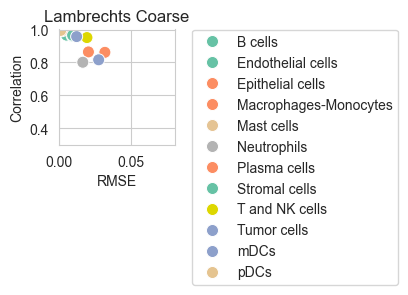

In [103]:
cell_palette.update({
    'CAFs': '#66C2A5',               # stromal/CAF family
    'Myeloid': '#FC8D62',            # macrophage/monocyte-heavy myeloid color you use
    'Cancer_Epithelial': '#8DA0CB',  # cancer family (distinct from stromal/immune)
    'Normal_Epithelial': '#FC8D62',  # epithelial/luminal family you already use
    'T-cells': '#FFD92F',            # T cells family
    'B-cells': '#66C2A5',            # B cells family
    'PVL': '#FC8D62',                # PVL family you set to luminal/orange
    'Endothelial': '#66C2A5',        # endothelial/stromal-like green
})
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(0.3, 1)
lambrechts_coarse_r_cell_avg_sub = lambrechts_coarse_r_cell_avg
lambrechts_coarse_rsme_cell_avg_sub = lambrechts_coarse_rsme_cell_avg

sns.scatterplot(data=lambrechts_coarse_r_cell_avg_sub.to_frame(name='Correlation').join(lambrechts_coarse_rsme_cell_avg_sub.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=lambrechts_coarse_r_cell_avg_sub.index, s=75, palette=cell_palette)
plt.title('Lambrechts Coarse')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_lambrechts_coarse.pdf', bbox_inches='tight')
plt.show()

# Wu resolution analysis

In [ ]:
import pandas as pd
import helper
wu_fine_folder = '../data/fig3/resolution_csv/allen_wu/wu_resolution_analysis_sim_fine_annot'
wu_normal_folder = '../data/fig3/resolution_csv/allen_wu/wu_resolution_analysis_sim_normal_annot'
wu_coarse_folder = '../data/fig3/resolution_csv/allen_wu/wu_resolution_analysis_sim_coarse_annot'

wu_fine_estimations = []
wu_fine_true =[]
wu_normal_estimations = []
wu_normal_true =[]
wu_coarse_estimations = []
wu_coarse_true =[]
for i in range(1,6):
    fine_estimation = pd.read_csv(wu_fine_folder + f'/replicate_{i}/deconvolution.csv', index_col=0)
    fine_estimation = fine_estimation.drop('Unknown', axis=1)
    fine_true = pd.read_csv(wu_fine_folder + f'/replicate_{i}/true_cell_fractions.csv', index_col=0)
    normal_estimation = pd.read_csv(wu_normal_folder + f'/replicate_{i}/deconvolution.csv', index_col=0)
    normal_estimation = normal_estimation.drop('Unknown', axis=1)
    normal_true = pd.read_csv(wu_normal_folder + f'/replicate_{i}/true_cell_fractions.csv', index_col=0)
    coarse_estimation = pd.read_csv(wu_coarse_folder + f'/replicate_{i}/deconvolution.csv', index_col=0)
    coarse_estimation = coarse_estimation.drop('Unknown', axis=1)
    coarse_true = pd.read_csv(wu_coarse_folder + f'/replicate_{i}/true_cell_fractions.csv', index_col=0)
    wu_fine_estimations.append(fine_estimation)
    wu_normal_estimations.append(normal_estimation)
    wu_coarse_estimations.append(coarse_estimation)
    wu_fine_true.append(fine_true)
    wu_normal_true.append(normal_true)
    wu_coarse_true.append(coarse_true)

wu_fine_evaluations = []
wu_fine_evalutaions_cell_types = []
wu_normal_evaluations = []
wu_normal_evaluations_cell_types = []
wu_coarse_evaluations = []
wu_coarse_evaluations_cell_types = []
fine_cell_types = None
normal_cell_types = None
coarse_cell_types = None
for i in range(5):
    wu_true = wu_fine_true[i]
    wu_estimation = wu_fine_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    fine_cell_types = wu_estimation.index
    fine_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(fine_evaluation)
    wu_fine_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_fine_evalutaions_cell_types.append((rsmes, rs, ps))

    wu_true = wu_normal_true[i]
    wu_estimation = wu_normal_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    normal_cell_types = wu_estimation.index
    normal_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(normal_evaluation)
    wu_normal_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_normal_evaluations_cell_types.append((rsmes, rs, ps))

    wu_true = wu_coarse_true[i]
    wu_estimation = wu_coarse_estimations[i].T
    # sort columns and index to match
    wu_true = wu_true.sort_index().sort_index(axis=1)
    wu_estimation = wu_estimation.sort_index().sort_index(axis=1)
    coarse_cell_types = wu_estimation.index
    coarse_evaluation = helper.create_evaluation_df(wu_true, wu_estimation)
    rsme, r, p = helper.evaulate_total_df(coarse_evaluation)
    wu_coarse_evaluations.append((rsme, r, p))
    rsmes, rs, ps = helper.evaluate_by_cell_type(wu_true, wu_estimation)
    wu_coarse_evaluations_cell_types.append((rsmes, rs, ps))

# average values
wu_fine_rsmes = [x[0] for x in wu_fine_evaluations]
wu_fine_rsme_avg = sum(wu_fine_rsmes) / len(wu_fine_rsmes)
wu_fine_r_values = [x[1] for x in wu_fine_evaluations]
wu_fine_r_avg = sum(wu_fine_r_values) / len(wu_fine_r_values)
wu_normal_rsmes = [x[0] for x in wu_normal_evaluations]
wu_normal_rsme_avg = sum(wu_normal_rsmes) / len(wu_normal_rsmes)
wu_normal_r_values = [x[1] for x in wu_normal_evaluations]
wu_normal_r_avg = sum(wu_normal_r_values) / len(wu_normal_r_values)
wu_coarse_rsmes = [x[0] for x in wu_coarse_evaluations]
wu_coarse_rsme_avg = sum(wu_coarse_rsmes) / len(wu_coarse_rsmes)
wu_coarse_r_values = [x[1] for x in wu_coarse_evaluations]
wu_coarse_r_avg = sum(wu_coarse_r_values) / len(wu_coarse_r_values)

wu_fine_rsmes_cell = [x[0] for x in wu_fine_evalutaions_cell_types]
wu_fine_rsme_cell_avg = pd.DataFrame(wu_fine_rsmes_cell).mean()
# set index to fine_cell_types
wu_fine_rsme_cell_avg.index = fine_cell_types
wu_fine_r_cell = [x[2] for x in wu_fine_evalutaions_cell_types]
wu_fine_r_cell_avg = pd.DataFrame(wu_fine_r_cell).mean()
# set index to fine_cell_types
wu_fine_r_cell_avg.index = fine_cell_types
wu_normal_rsmes_cell = [x[0] for x in wu_normal_evaluations_cell_types]
wu_normal_rsme_cell_avg = pd.DataFrame(wu_normal_rsmes_cell).mean()
wu_normal_rsme_cell_avg.index = normal_cell_types
wu_normal_r_cell = [x[2] for x in wu_normal_evaluations_cell_types]
wu_normal_r_cell_avg = pd.DataFrame(wu_normal_r_cell).mean()
wu_normal_r_cell_avg.index = normal_cell_types
wu_coarse_rsmes_cell = [x[0] for x in wu_coarse_evaluations_cell_types]
wu_coarse_rsme_cell_avg = pd.DataFrame(wu_coarse_rsmes_cell).mean()
wu_coarse_rsme_cell_avg.index = coarse_cell_types
wu_coarse_r_cell = [x[2] for x in wu_coarse_evaluations_cell_types]
wu_coarse_r_cell_avg = pd.DataFrame(wu_coarse_r_cell).mean()
wu_coarse_r_cell_avg.index = coarse_cell_types

In [ ]:
# plot results
import seaborn as sns
import matplotlib.pyplot as plt
# Additions for missing keys
cell_palette.update({
    # Endothelial / vascular
    'Endothelial_ACKR1': '#66C2A5',                 # stromal-like green
    'Endothelial_CXCL12': '#66C2A5',
    'Endothelial_Lymphatic_LYVE1': '#66C2A5',
    'Endothelial_RGS5': '#66C2A5',

    # CAFs / stromal
    'CAFs_MSC_iCAF-like': '#66C2A5',
    'CAFs_myCAF-like': '#66C2A5',
    'Myoepithelial': '#66C2A5',

    # Luminal / epithelial (non-cancer)
    'Mature_Luminal': '#FC8D62',
    'Luminal_Progenitors': '#FC8D62',

    # PVL states (not sure what PVL stands for in your context; use luminal family)
    'PVL_Immature': '#FC8D62',
    'PVL_Differentiated': '#FC8D62',
    'Cycling_PVL': '#B3B3B3',

    # B lineage
    'B_cells_Naive': '#66C2A5',
    'B_cells_Memory': '#66C2A5',
    'Plasmablasts': '#FC8D62',

    # NK / T / NKT
    'NK_cells': '#DDD700',
    'NKT_cells': '#DDD700',
    'T_cells_CD4+': '#B3B3B3',
    'T_cells_CD8+': '#A6D854',
    'Cycling_T-cells': '#B3B3B3',

    # Myeloid
    'Monocyte': '#E78AC3',
    'Macrophage': '#FC8D62',
    'DCs': '#8DA0CB',
    'Cycling_Myeloid': '#B3B3B3',

    # Cancer states (group into a consistent cancer palette)
    'Cancer_Basal_SC': '#8DA0CB',                   # similar to "Lusc" family
    'Cancer_LumA_SC': '#66C2A5',                    # similar to "Brca" family
    'Cancer_LumB_SC': '#FC8D62',                    # similar to "Luad/CPE" family
    'Cancer_Her2_SC': '#E78AC3',                    # standout magenta family
    'Cancer_Cycling': '#B3B3B3',
    'Cancer_Cycling': '#B3B3B3',  # (duplicate key safe; last wins)
})
color_palette = sns.color_palette("tab20")[0:8]
color_palette.append((0.01, 0.01, 0.01))
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(0.3, 1)
sns.scatterplot(data=wu_normal_r_cell_avg.to_frame(name='Correlation').join(wu_normal_rsme_cell_avg.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=wu_normal_r_cell_avg.index, s=75, palette=cell_palette)
plt.title('Wu Normal')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_wu_normal.pdf', bbox_inches='tight')
plt.show()


In [ ]:
cell_palette.update({
    # ---- T cells / NK / NKT subclusters ----
    'T_cells_c0_CD4+_CCR7': '#B3B3B3',              # CD4 family
    'T_cells_c1_CD4+_IL7R': '#B3B3B3',              # CD4 family
    'T_cells_c2_CD4+_T-regs_FOXP3': '#52A0A0',      # Tregs
    'T_cells_c3_CD4+_Tfh_CXCL13': '#B3B3B3',        # CD4 family
    'T_cells_c4_CD8+_ZFP36': '#A6D854',             # CD8 family
    'T_cells_c5_CD8+_GZMK': '#A6D854',              # CD8 family
    'T_cells_c6_IFIT1': '#FFD92F',                  # general T cells (or interferon-ish)
    'T_cells_c7_CD8+_IFNG': '#A6D854',              # CD8 effector
    'T_cells_c8_CD8+_LAG3': '#A6D854',              # exhausted CD8
    'T_cells_c9_NK_cells_AREG': '#DDD700',          # NK family
    'T_cells_c10_NKT_cells_FCGR3A': '#DDD700',      # NKT/NK-like
    'T_cells_c11_MKI67': '#B3B3B3',                 # cycling -> neutral

    # ---- Myeloid subclusters ----
    'Myeloid_c0_DC_LAMP3': '#8DA0CB',               # DC family
    'Myeloid_c3_cDC1_CLEC9A': '#A3C292',            # cDC1 (matches your cDC1)
    'Myeloid_c11_cDC2_CD1C': '#A1C090',             # cDC2 (matches your cDC2)
    'Myeloid_c4_DCs_pDC_IRF7': '#E5C494',           # pDC family
    'Myeloid_c12_Monocyte_1_IL1B': '#E78AC3',       # monocytes
    'Myeloid_c8_Monocyte_2_S100A9': '#E78AC3',      # monocytes
    'Myeloid_c7_Monocyte_3_FCGR3A': '#E78AC3',      # monocytes (non-classical-ish but keep same family)
    'Myeloid_c5_Macrophage_3_SIGLEC1': '#FC8D62',   # macrophage family
    'Myeloid_c10_Macrophage_1_EGR1': '#FC8D62',     # macrophage family
    'Myeloid_c9_Macrophage_2_CXCL10': '#FC8D62',    # macrophage family
    'Myeloid_c1_LAM1_FABP5': '#FC8D62',             # macrophage-like (LAM)
    'Myeloid_c2_LAM2_APOE': '#FC8D62',              # macrophage-like (LAM)

    # ---- CAF subclusters ----
    'CAFs_Transitioning_s3': '#66C2A5',
    'CAFs_MSC_iCAF-like_s1': '#66C2A5',
    'CAFs_MSC_iCAF-like_s2': '#66C2A5',
    'CAFs_myCAF_like_s4': '#66C2A5',
    'CAFs_myCAF_like_s5': '#66C2A5',

    # ---- PVL subclusters ----
    'PVL_Immature_s1': '#FC8D62',
    'PVL_Immature_s2': '#FC8D62',
    'PVL_Differentiated_s3': '#FC8D62',
})
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(-0.3, 1)
sns.scatterplot(data=wu_fine_r_cell_avg.to_frame(name='Correlation').join(wu_fine_rsme_cell_avg.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=wu_fine_r_cell_avg.index, s=75, palette=cell_palette)
plt.title('Wu Fine')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_wu_fine.pdf', bbox_inches='tight')
plt.show()

In [ ]:
cell_palette.update({
    'CAFs': '#66C2A5',               # stromal/CAF family
    'Myeloid': '#FC8D62',            # macrophage/monocyte-heavy myeloid color you use
    'Cancer_Epithelial': '#8DA0CB',  # cancer family (distinct from stromal/immune)
    'Normal_Epithelial': '#FC8D62',  # epithelial/luminal family you already use
    'T-cells': '#FFD92F',            # T cells family
    'B-cells': '#66C2A5',            # B cells family
    'PVL': '#FC8D62',                # PVL family you set to luminal/orange
    'Endothelial': '#66C2A5',        # endothelial/stromal-like green
})
sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
# set y lim from 0 to 1
plt.xlim(0, 0.08)
plt.ylim(0.3, 1)
sns.scatterplot(data=wu_coarse_r_cell_avg.to_frame(name='Correlation').join(wu_coarse_rsme_cell_avg.to_frame(name='RMSE')), x='RMSE', y='Correlation', hue=wu_coarse_r_cell_avg.index, s=75, palette=cell_palette)
plt.title('Wu Coarse')
#legend in two rows
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
#tight layout
#save the whole figure
plt.savefig('../figures/3d_scatter_wu_coarse.pdf', bbox_inches='tight')
plt.show()

## Allen resolution Analysis

In [ ]:
import pandas as pd
import helper

# add missing Allen palette keys
cell_palette.update({
    # broad groups (normal)
    'Astro': '#66C2A5',
    'Endo': '#66C2A5',
    'Excit': '#A6D854',
    'Inhib': '#FFD92F',
    'Micro': '#FC8D62',
    'OPC': '#8DA0CB',
    'Oligo': '#8DA0CB',

    # fine-grained groups
    'Endo_fine': '#66C2A5',
    'VLMC': '#66C2A5',
    'Micro-PVM': '#FC8D62',

    # excitatory subclasses
    'L2/3_IT': '#A6D854',
    'L5/6_NP': '#A6D854',
    'L5_ET': '#A6D854',
    'L5_IT': '#A6D854',
    'L6_CT': '#A6D854',
    'L6_IT': '#A6D854',
    'L6_IT_Car3': '#A6D854',
    'L6b': '#A6D854',

    # inhibitory subclasses
    'Lamp5': '#FFD92F',
    'Pvalb': '#FFD92F',
    'Sncg': '#FFD92F',
    'Sst': '#FFD92F',
    'Sst_Chodl': '#FFD92F',
    'Vip': '#FFD92F',
})

allen_fine_folder = '../data/fig3/resolution_csv/allen_wu/allen_resolution_analysis_sim_fine_annot'
allen_normal_folder = '../data/fig3/resolution_csv/allen_wu/allen_resolution_analysis_sim_normal_annot'

allen_fine_estimations = []
allen_fine_true = []
allen_normal_estimations = []
allen_normal_true = []

for i in range(1, 6):
    fine_estimation = pd.read_csv(allen_fine_folder + f'/replicate_{i}/deconvolution.csv', index_col=0)
    if 'Unknown' in fine_estimation.columns:
        fine_estimation = fine_estimation.drop('Unknown', axis=1)
    fine_true = pd.read_csv(allen_fine_folder + f'/replicate_{i}/true_cell_fractions.csv', index_col=0)

    normal_estimation = pd.read_csv(allen_normal_folder + f'/replicate_{i}/deconvolution.csv', index_col=0)
    if 'Unknown' in normal_estimation.columns:
        normal_estimation = normal_estimation.drop('Unknown', axis=1)
    normal_true = pd.read_csv(allen_normal_folder + f'/replicate_{i}/true_cell_fractions.csv', index_col=0)

    allen_fine_estimations.append(fine_estimation)
    allen_fine_true.append(fine_true)
    allen_normal_estimations.append(normal_estimation)
    allen_normal_true.append(normal_true)

allen_fine_evaluations = []
allen_fine_evalutaions_cell_types = []
allen_normal_evaluations = []
allen_normal_evaluations_cell_types = []

fine_cell_types_list = []
normal_cell_types_list = []

for i in range(5):
    allen_true = allen_fine_true[i]
    allen_estimation = allen_fine_estimations[i].T
    allen_true = allen_true.sort_index().sort_index(axis=1)
    allen_estimation = allen_estimation.sort_index().sort_index(axis=1)
    # match columns and index to avoid length mismatches
    allen_true, allen_estimation = helper.match_dfs(allen_true, allen_estimation)
    fine_cell_types_list.append(allen_estimation.index)
    fine_evaluation = helper.create_evaluation_df(allen_true, allen_estimation)
    rsme, r, p = helper.evaulate_total_df(fine_evaluation)
    allen_fine_evaluations.append((rsme, r, p))
    rsmes, ps,rs = helper.evaluate_by_cell_type(allen_true, allen_estimation)
    allen_fine_evalutaions_cell_types.append((rsmes, rs, ps))

    allen_true = allen_normal_true[i]
    allen_estimation = allen_normal_estimations[i].T
    # match columns and index to avoid length mismatches
    allen_true, allen_estimation = helper.match_dfs(allen_true, allen_estimation)
    normal_cell_types_list.append(allen_estimation.index)
    normal_evaluation = helper.create_evaluation_df(allen_true, allen_estimation)
    rsme, r, p = helper.evaulate_total_df(normal_evaluation)
    allen_normal_evaluations.append((rsme, r, p))
    rsmes, ps, rs = helper.evaluate_by_cell_type(allen_true, allen_estimation)
    allen_normal_evaluations_cell_types.append((rsmes, rs, ps))

# average values
allen_fine_rsmes = [x[0] for x in allen_fine_evaluations]
allen_fine_rsme_avg = sum(allen_fine_rsmes) / len(allen_fine_rsmes)
allen_fine_r_values = [x[1] for x in allen_fine_evaluations]
allen_fine_r_avg = sum(allen_fine_r_values) / len(allen_fine_r_values)

allen_normal_rsmes = [x[0] for x in allen_normal_evaluations]
allen_normal_rsme_avg = sum(allen_normal_rsmes) / len(allen_normal_rsmes)
allen_normal_r_values = [x[1] for x in allen_normal_evaluations]
allen_normal_r_avg = sum(allen_normal_r_values) / len(allen_normal_r_values)

# robust per-cell-type averages (handle missing types across replicates)

def _avg_cell_metrics(eval_cells, cell_type_lists):
    rsme_series = []
    r_series = []
    for (rsmes, rs, _ps), cell_types in zip(eval_cells, cell_type_lists):
        rsme_series.append(pd.Series(rsmes, index=cell_types))
        r_series.append(pd.Series(rs, index=cell_types))
    rsme_df = pd.concat(rsme_series, axis=1)
    r_df = pd.concat(r_series, axis=1)
    return rsme_df.mean(axis=1), r_df.mean(axis=1)

allen_fine_rsme_cell_avg, allen_fine_r_cell_avg = _avg_cell_metrics(
    allen_fine_evalutaions_cell_types,
    fine_cell_types_list,
)
allen_normal_rsme_cell_avg, allen_normal_r_cell_avg = _avg_cell_metrics(
    allen_normal_evaluations_cell_types,
    normal_cell_types_list,
)


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
plt.xlim(0, 0.02)
plt.ylim(0.9, 1)

sns.scatterplot(
    data=allen_normal_r_cell_avg.to_frame(name='Correlation').join(
        allen_normal_rsme_cell_avg.to_frame(name='RMSE')
    ),
    x='RMSE',
    y='Correlation',
    hue=allen_normal_r_cell_avg.index,
    s=75,
    palette=cell_palette,
)
plt.title('Allen Normal')
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
plt.savefig('../figures/3d_scatter_allen_normal.pdf', bbox_inches='tight')
plt.show()


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.figure(figsize=(1.5, 1.5))
plt.xlim(0, 0.02)
plt.ylim(0.9, 1)

sns.scatterplot(
    data=allen_fine_r_cell_avg.to_frame(name='Correlation').join(
        allen_fine_rsme_cell_avg.to_frame(name='RMSE')
    ),
    x='RMSE',
    y='Correlation',
    hue=allen_fine_r_cell_avg.index,
    s=75,
    palette=cell_palette,
)
plt.title('Allen Fine')
plt.legend(bbox_to_anchor=(1.15, 1), loc=2, borderaxespad=0., ncol=1)
plt.savefig('../figures/3d_scatter_allen_fine.pdf', bbox_inches='tight')
plt.show()


## Figure 3E

# 3D

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
# Load the spatial data
spatial_df = pd.read_csv('../data/fig3/spillover_total.csv', index_col=0)
spatial_df = spatial_df.drop('Total', axis=1)

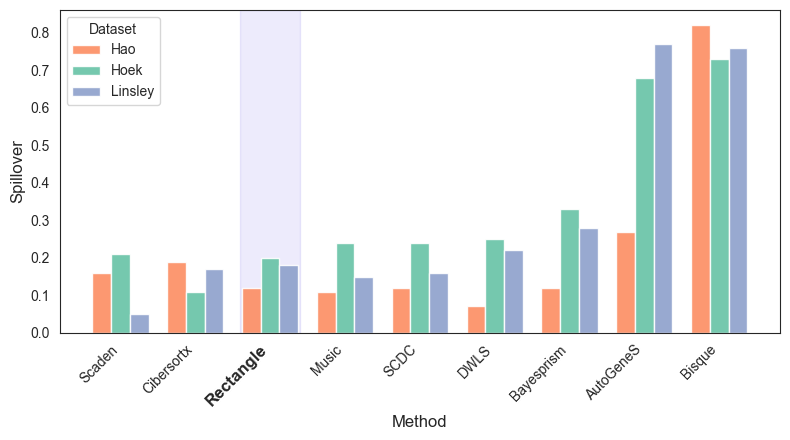


Spillover Summary:
             Hao  Hoek  Linsley
Method                         
Scaden      0.16  0.21     0.05
Cibersortx  0.19  0.11     0.17
Rectangle   0.12  0.20     0.18
Music       0.11  0.24     0.15
SCDC        0.12  0.24     0.16
DWLS        0.07  0.25     0.22
Bayesprism  0.12  0.33     0.28
AutoGeneS   0.27  0.68     0.77
Bisque      0.82  0.73     0.76

Mean spillover per method:
Method
Scaden        0.140
Cibersortx    0.157
Rectangle     0.167
Music         0.167
SCDC          0.173
DWLS          0.180
Bayesprism    0.243
AutoGeneS     0.573
Bisque        0.770
dtype: float64


In [4]:
sns.set_style("white")
# Sort by the mean performance across datasets (lower is better)
spatial_df['Mean'] = spatial_df[['Hao', 'Hoek', 'Linsley']].mean(axis=1)
spatial_df = spatial_df.sort_values('Mean')
spatial_df = spatial_df.drop('Mean', axis=1)

# Create figure
fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bar chart
datasets = ['Hao', 'Hoek', 'Linsley']
colors = ['#FC8D62', '#66C2A5', '#8DA0CB']  # Orange, Teal, Blue - publication-quality

methods = spatial_df.index.tolist()
x = np.arange(len(methods))
width = 0.25

# Soft, eye-friendly color palette

for i, dataset in enumerate(datasets):
    offset = width * (i - 1)
    bars = ax.bar(x + offset, spatial_df[dataset], width, label=dataset, color=colors[i], alpha=0.9)

# Highlight Rectangle with a vertical span and bold x-label
if 'Rectangle' in methods:
    rect_idx = methods.index('Rectangle')
    ax.axvspan(rect_idx - 0.4, rect_idx + 0.4, alpha=0.12, color='#6C5CE7', zorder=0)

    # Make Rectangle label bold
    labels = ax.get_xticklabels()
    labels[rect_idx].set_weight('bold')
    labels[rect_idx].set_fontsize(12)

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Spillover', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=45, ha='right')
ax.legend(title='Dataset', loc='upper left')
# Remove grid lines
ax.grid(False)

plt.tight_layout()
plt.savefig('../figures/fig3d_spatial_spillover.pdf', dpi=300, bbox_inches='tight')
plt.show()

print("\nSpillover Summary:")
print(spatial_df.round(3))
print("\nMean spillover per method:")
print(spatial_df.mean(axis=1).round(3).sort_values())


In [ ]:
## circle plot